# A/B Test Significance Analysis — Checkout Experiment (Control_A vs Variant_B)

**Data:** `data/raw_experiment_logs.csv` — 1,200 user-interaction events, 400 users, 10–23 Mar 2026
(synthetic; see the README's Data provenance section)
**Design:** see `data/experiment_design.md` — user-level randomization, checkout completion is the
primary metric.

**The order of this notebook is the method.** No effect is read until assignment integrity is proven:
1. Load and inspect the logs
2. Data quality + assignment integrity (contamination, SRM, covariate balance)
3. Primary metric: effect size, confidence interval, significance tests
4. Power accounting — what could this sample actually detect?
5. Peeking / stability diagnostics
6. Secondary metrics (funnel, session duration guardrail)
7. Heterogeneity (device, segment) — with multiple-comparison discipline
8. Bayesian cross-check
9. Decision

The load cell below resolves the CSV from either the repo root or `python/`, so the notebook runs
wherever the kernel starts. Every figure in it is re-derived independently by `verify_analysis.py`.

## 1. Load the logs

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", "{:.4f}".format)

In [2]:
from pathlib import Path


def locate(relative):
    """Resolve a repo-relative path whether the kernel starts at the repo root,
    inside python/, or in any parent of either."""
    cwd = Path.cwd().resolve()
    here = Path(globals().get("__file__", ".")).resolve()
    for root in [cwd, *cwd.parents, here, *here.parents]:
        if (root / relative).exists():
            return root / relative
    raise FileNotFoundError(relative)


df = pd.read_csv(locate("data/raw_experiment_logs.csv"), parse_dates=["timestamp"])
df.head(9)

,user_id,session_id,timestamp,device_type,user_segment,variant,event_name,page_location,time_spent_sec,is_converted
0,USR_2172,SES_8172,2026-03-10 08:23:53,Mobile,Free,Control_A,page_view,/checkout,9,0
1,USR_2172,SES_8172,2026-03-10 08:24:03,Mobile,Free,Control_A,checkout_start,/checkout-step1,35,0
2,USR_2172,SES_8172,2026-03-10 08:24:39,Mobile,Free,Control_A,drop_off,/checkout-step1,36,0
3,USR_2031,SES_8031,2026-03-10 10:24:00,Desktop,Premium,Variant_B,page_view,/checkout,11,0
4,USR_2031,SES_8031,2026-03-10 10:24:14,Desktop,Premium,Variant_B,checkout_start,/checkout-step1,29,0
5,USR_2031,SES_8031,2026-03-10 10:24:46,Desktop,Premium,Variant_B,checkout_complete,/checkout-confirmation,60,1
6,USR_2161,SES_8161,2026-03-10 11:25:38,Mobile,Premium,Control_A,page_view,/checkout,5,0
7,USR_2161,SES_8161,2026-03-10 11:25:44,Mobile,Premium,Control_A,checkout_start,/checkout-step1,21,0
8,USR_2161,SES_8161,2026-03-10 11:26:08,Mobile,Premium,Control_A,drop_off,/checkout-step1,44,0


In [3]:
print("events:", len(df))
print("users:", df["user_id"].nunique())
print("sessions:", df["session_id"].nunique())
print("window:", df["timestamp"].min(), "->", df["timestamp"].max())
df.shape

events: 1200
users: 400
sessions: 400
window: 2026-03-10 08:23:53 -> 2026-03-23 22:19:27


(1200, 10)

In [4]:
df.dtypes

user_id                      str
session_id                   str
timestamp         datetime64[us]
device_type                  str
user_segment                 str
variant                      str
event_name                   str
page_location                str
time_spent_sec             int64
is_converted               int64
dtype: object

In [5]:
df.isna().sum()

user_id           0
session_id        0
timestamp         0
device_type       0
user_segment      0
variant           0
event_name        0
page_location     0
time_spent_sec    0
is_converted      0
dtype: int64

In [6]:
df["event_name"].value_counts()

event_name
page_view            400
checkout_start       400
drop_off             206
checkout_complete    194
Name: count, dtype: int64

In [7]:
pd.crosstab(df["event_name"], df["page_location"])

page_location,/checkout,/checkout-confirmation,/checkout-step1
event_name,,,
checkout_complete,0,194,0
checkout_start,0,0,400
drop_off,0,0,206
page_view,400,0,0


Every session follows the same 3-event skeleton: `page_view` (/checkout) → `checkout_start`
(/checkout-step1) → either `checkout_complete` (/checkout-confirmation, converted) or
`drop_off` (/checkout-step1, not converted).

## 2. Data quality and assignment integrity

In [8]:
print("duplicate rows:", df.duplicated().sum())
print("events per session:")
print(df.groupby("session_id").size().value_counts())

duplicate rows: 0
events per session:
3    400
Name: count, dtype: int64


In [9]:
# contamination check: a user (or session) must live in exactly ONE variant
print("users in both variants:",
      (df.groupby("user_id")["variant"].nunique() > 1).sum())
print("sessions in both variants:",
      (df.groupby("session_id")["variant"].nunique() > 1).sum())
print("sessions per user:",
      df.groupby("user_id")["session_id"].nunique().value_counts().to_dict())

users in both variants: 0
sessions in both variants: 0
sessions per user: {1: 400}


In [10]:
# attribute stability inside a session
print("device drift in session:",
      (df.groupby("session_id")["device_type"].nunique() > 1).sum())
print("segment drift in session:",
      (df.groupby("session_id")["user_segment"].nunique() > 1).sum())

device drift in session: 0
segment drift in session: 0


In [11]:
# the conversion flag must agree with the terminal event
conv_events = df.loc[df["is_converted"] == 1, "event_name"].unique()
print("events carrying is_converted = 1:", conv_events)
print("checkout_complete rows with is_converted = 0:",
      ((df["event_name"] == "checkout_complete") & (df["is_converted"] == 0)).sum())

events carrying is_converted = 1: <ArrowStringArray>
['checkout_complete']
Length: 1, dtype: str
checkout_complete rows with is_converted = 0: 0


Integrity is clean: no duplicates, no contamination, no drift, the flag reconciles with the
terminal event, and every session has exactly 3 events. Now build the analysis grain.

## 3. Build the user-level cohort
The randomization unit is the **user**, so the analysis table is one row per user.
(In this run each user has exactly one session, so user-level and session-level rates are identical —
that is verified, not assumed, by the checks above.)

In [12]:
users = df.groupby("user_id").agg(
    variant=("variant", "first"),
    device_type=("device_type", "first"),
    user_segment=("user_segment", "first"),
    converted=("is_converted", "max"),
    session_duration_sec=("time_spent_sec", "max"),
    first_seen=("timestamp", "min"),
).reset_index()
users["assignment_date"] = users["first_seen"].dt.date
users.head()

,user_id,variant,device_type,user_segment,converted,session_duration_sec,first_seen,assignment_date
0,USR_2001,Variant_B,Desktop,Enterprise,0,41,2026-03-20 09:01:47,2026-03-20
1,USR_2002,Control_A,Mobile,Free,1,39,2026-03-21 22:34:05,2026-03-21
2,USR_2003,Variant_B,Desktop,Enterprise,1,25,2026-03-18 17:01:35,2026-03-18
3,USR_2004,Variant_B,Mobile,Free,1,46,2026-03-22 20:10:44,2026-03-22
4,USR_2005,Control_A,Mobile,Free,0,43,2026-03-11 09:24:06,2026-03-11


In [13]:
users["variant"].value_counts()

variant
Control_A    205
Variant_B    195
Name: count, dtype: int64

In [14]:
A = users[users["variant"] == "Control_A"]
B = users[users["variant"] == "Variant_B"]
print("Control_A users:", len(A), "| Variant_B users:", len(B))

Control_A users: 205 | Variant_B users: 195


## 4. SRM check — is the split itself trustworthy?

In [15]:
# expected split is 50/50 -> 200 / 200
observed = np.array([len(A), len(B)])
expected = np.array([len(users) / 2, len(users) / 2])
chi2_srm = ((observed - expected) ** 2 / expected).sum()
p_srm = stats.chi2.sf(chi2_srm, df=1)
print("observed:", observed, "expected:", expected)
print("SRM chi-square = %.3f, p = %.4f" % (chi2_srm, p_srm))

observed: [205 195] expected: [200. 200.]
SRM chi-square = 0.250, p = 0.6171


**SRM: chi-square 0.250, p = 0.617 → no sample ratio mismatch.** The 205/195 split is ordinary
random variation around 50/50. If this had failed (p < 0.001 convention), the correct action would be
to stop and debug the assignment pipeline, not to analyse the effect.

## 5. Covariate balance — did randomization equalise the arms?

In [16]:
device_balance = pd.crosstab(users["variant"], users["device_type"], normalize="index") * 100
device_balance.round(2)

device_type,Desktop,Mobile,Tablet
variant,,,
Control_A,47.8000,40.0000,12.2000
Variant_B,46.6700,41.5400,11.7900


In [17]:
chi2_dev, p_dev, _, _ = stats.chi2_contingency(pd.crosstab(users["variant"], users["device_type"]))
print("device balance chi-square = %.3f, p = %.3f" % (chi2_dev, p_dev))

device balance chi-square = 0.099, p = 0.952


In [18]:
segment_balance = pd.crosstab(users["variant"], users["user_segment"], normalize="index") * 100
segment_balance.round(2)

user_segment,Enterprise,Free,Premium
variant,,,
Control_A,14.1500,55.6100,30.2400
Variant_B,20.5100,53.8500,25.6400


In [19]:
chi2_seg, p_seg, _, _ = stats.chi2_contingency(pd.crosstab(users["variant"], users["user_segment"]))
print("segment balance chi-square = %.3f, p = %.3f" % (chi2_seg, p_seg))

segment balance chi-square = 3.161, p = 0.206


**Balance holds:** device mix (p = 0.952) and segment mix (p = 0.206) are statistically
indistinguishable across arms, so neither can confound the headline comparison.
The arms differ only in the treatment. Now the effect can be read.

## 6. Primary metric — checkout completion rate

In [20]:
scorecard = users.groupby("variant").agg(
    users=("user_id", "count"),
    conversions=("converted", "sum"),
).reset_index()
scorecard["conversion_rate_pct"] = scorecard["conversions"] / scorecard["users"] * 100
scorecard

,variant,users,conversions,conversion_rate_pct
0,Control_A,205,96,46.8293
1,Variant_B,195,98,50.2564


In [21]:
p_a = A["converted"].mean()
p_b = B["converted"].mean()
diff_pp = (p_b - p_a) * 100
rel_lift = (p_b - p_a) / p_a * 100
print("Control_A rate: %.2f%%  (%d/%d)" % (p_a * 100, A["converted"].sum(), len(A)))
print("Variant_B rate: %.2f%%  (%d/%d)" % (p_b * 100, B["converted"].sum(), len(B)))
print("absolute difference: %+.2f percentage points" % diff_pp)
print("relative lift: %+.2f%%" % rel_lift)

Control_A rate: 46.83%  (96/205)
Variant_B rate: 50.26%  (98/195)
absolute difference: +3.43 percentage points
relative lift: +7.32%


In [22]:
# 95% CI for the difference (unpooled standard error)
se_diff = np.sqrt(p_a * (1 - p_a) / len(A) + p_b * (1 - p_b) / len(B))
ci_low, ci_high = diff_pp - 1.96 * se_diff * 100, diff_pp + 1.96 * se_diff * 100
print("95%% CI for the difference: %+.2f to %+.2f pp" % (ci_low, ci_high))

95% CI for the difference: -6.37 to +13.22 pp


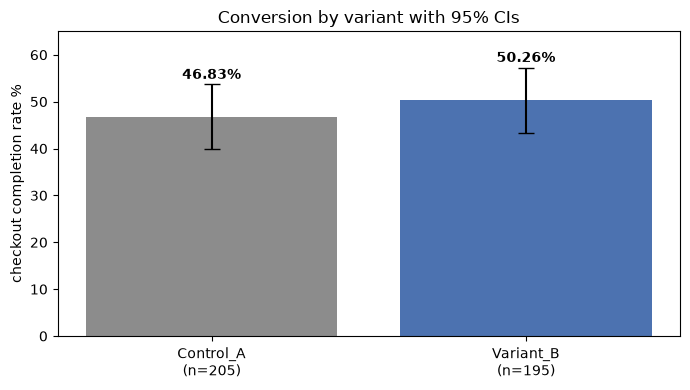

In [23]:
rates = [p_a * 100, p_b * 100]
errs = [1.96 * np.sqrt(p * (1 - p) / n) * 100
        for p, n in [(p_a, len(A)), (p_b, len(B))]]
plt.figure(figsize=(7, 4))
plt.bar(["Control_A\n(n=205)", "Variant_B\n(n=195)"], rates, yerr=errs,
        capsize=6, color=["#8C8C8C", "#4C72B0"])
for i, v in enumerate(rates):
    plt.text(i, v + errs[i] + 1.2, "%.2f%%" % v, ha="center", fontweight="bold")
plt.ylabel("checkout completion rate %")
plt.title("Conversion by variant with 95% CIs")
plt.ylim(0, 65)
plt.tight_layout()
plt.show()

**Point estimate: +3.43 pp (+7.32% relative). But the 95% CI runs from −6.37 pp to +13.22 pp** —
the data are consistent with Variant_B being meaningfully worse, no different, or much better.
The next section asks whether that interval is just wide, or decisive.

## 7. Significance tests

In [24]:
# two-proportion z-test (pooled standard error under H0)
p_pool = users["converted"].mean()
se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / len(A) + 1 / len(B)))
z_stat = (p_b - p_a) / se_pool
p_z = 2 * stats.norm.sf(abs(z_stat))
print("z = %.3f, two-sided p = %.4f" % (z_stat, p_z))

z = 0.686, two-sided p = 0.4930


In [25]:
# same table as a chi-square test (must agree: chi2 = z^2)
table = np.array([[A["converted"].sum(), len(A) - A["converted"].sum()],
                  [B["converted"].sum(), len(B) - B["converted"].sum()]])
chi2, p_chi, _, _ = stats.chi2_contingency(table, correction=False)
print("chi-square = %.4f, p = %.4f" % (chi2, p_chi))

chi-square = 0.4699, p = 0.4930


In [26]:
# Fisher's exact test as a small-sample robustness check
odds, p_fisher = stats.fisher_exact(table)
print("Fisher exact p = %.4f (odds ratio %.3f)" % (p_fisher, odds))

Fisher exact p = 0.5483 (odds ratio 0.872)


**All three tests agree: p ≈ 0.49 (Fisher 0.55).** There is no statistically detectable
difference in checkout completion between the variants in this run. That is *not* the same as
"there is no difference" — which is exactly what the power analysis quantifies next.

## 8. Power accounting — what could 200 users per arm actually detect?

In [27]:
def power_two_prop(p1, p2, n, alpha=0.05):
    se = np.sqrt(p1 * (1 - p1) / n + p2 * (1 - p2) / n)
    return stats.norm.cdf(abs(p2 - p1) / se - stats.norm.ppf(1 - alpha / 2))

def required_n_per_arm(p1, p2, power=0.80, alpha=0.05):
    k = (stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)) ** 2
    return int(np.ceil(k * (p1 * (1 - p1) + p2 * (1 - p2)) / (p2 - p1) ** 2))

In [28]:
print("power of this run for the observed +3.43 pp effect: %.1f%%"
      % (power_two_prop(p_a, p_b, 200) * 100))
mde_pp = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * se_diff * 100
print("minimum detectable effect at 80%% power, this sample: %.1f pp" % mde_pp)

power of this run for the observed +3.43 pp effect: 10.1%
minimum detectable effect at 80% power, this sample: 14.0 pp


In [29]:
scenarios = pd.DataFrame({
    "true_effect_pp": [3.43, 5.0, 10.0],
    "required_users_per_arm": [
        required_n_per_arm(p_a, p_b),
        required_n_per_arm(p_a, p_a + 0.05),
        required_n_per_arm(p_a, p_a + 0.10)],
})
scenarios

,true_effect_pp,required_users_per_arm
0,3.4300,3335
1,5.0000,1566
2,10.0000,388


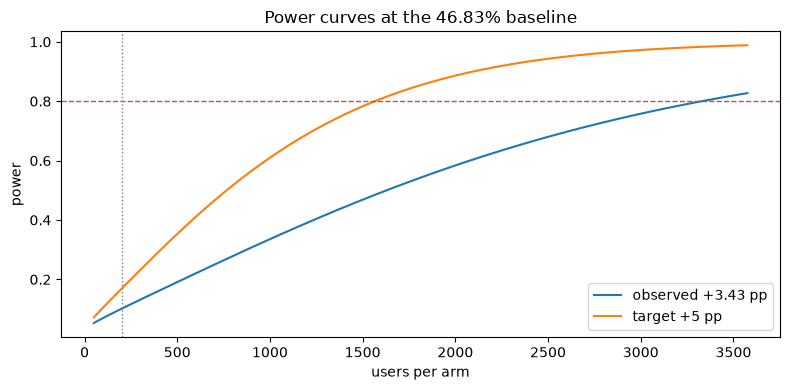

In [30]:
ns = np.arange(50, 3600, 25)
plt.figure(figsize=(8, 4))
plt.plot(ns, [power_two_prop(p_a, p_a + 0.0343, n) for n in ns], label="observed +3.43 pp")
plt.plot(ns, [power_two_prop(p_a, p_a + 0.05, n) for n in ns], label="target +5 pp")
plt.axhline(0.8, color="#C44E52", linestyle="--", linewidth=1)
plt.axvline(200, color="grey", linestyle=":", linewidth=1)
plt.xlabel("users per arm")
plt.ylabel("power")
plt.title("Power curves at the 46.83% baseline")
plt.legend()
plt.tight_layout()
plt.show()

**This experiment was only ever capable of confirming a very large effect.** With ~200 users
per arm, the minimum detectable effect at 80% power is ≈ **14 pp** — four times the observed
+3.43 pp. Power for the observed effect is ≈ **10%**: even if Variant_B truly is +3.43 pp better,
this design would miss it 9 times out of 10. To confirm +3.43 pp would take ≈ 3,335 users per arm;
a +5 pp target needs ≈ 1,566 per arm. "Not significant" here means **underpowered and
inconclusive**, not "no effect".

## 9. Peeking diagnostic — the cumulative readout over time

In [31]:
daily = users.groupby(["assignment_date", "variant"]).agg(
    users=("user_id", "count"), conversions=("converted", "sum")).reset_index()
daily = daily.pivot(index="assignment_date", columns="variant").fillna(0)
daily.columns = ["u_A", "u_B", "c_A", "c_B"]
daily[["n_A", "n_B"]] = daily[["u_A", "u_B"]].cumsum()
daily[["conv_A", "conv_B"]] = daily[["c_A", "c_B"]].cumsum()
daily["rate_A"] = daily["conv_A"] / daily["n_A"]
daily["rate_B"] = daily["conv_B"] / daily["n_B"]
daily["diff_pp"] = (daily["rate_B"] - daily["rate_A"]) * 100
pool = (daily["conv_A"] + daily["conv_B"]) / (daily["n_A"] + daily["n_B"])
se = np.sqrt(pool * (1 - pool) * (1 / daily["n_A"] + 1 / daily["n_B"]))
daily["p_value"] = 2 * stats.norm.sf(np.abs(daily["diff_pp"] / 100 / se))
daily.round(3)

,u_A,u_B,c_A,c_B,n_A,n_B,conv_A,conv_B,rate_A,rate_B,diff_pp,p_value
assignment_date,,,,,,,,,,,,
2026-03-10,20,9,7,5,20,9,7,5,0.3500,0.5560,20.5560,0.2980
2026-03-11,15,11,8,5,35,20,15,10,0.4290,0.5000,7.1430,0.6090
2026-03-12,14,16,7,6,49,36,22,16,0.4490,0.4440,-0.4540,0.9670
2026-03-13,16,10,8,5,65,46,30,21,0.4620,0.4570,-0.5020,0.9580
2026-03-14,18,17,6,7,83,63,36,28,0.4340,0.4440,1.0710,0.8970
2026-03-15,22,15,10,7,105,78,46,35,0.4380,0.4490,1.0620,0.8860
2026-03-16,14,9,8,6,119,87,54,41,0.4540,0.4710,1.7480,0.8040
2026-03-17,14,19,5,8,133,106,59,49,0.4440,0.4620,1.8660,0.7730
2026-03-18,12,9,5,6,145,115,64,55,0.4410,0.4780,3.6880,0.5530


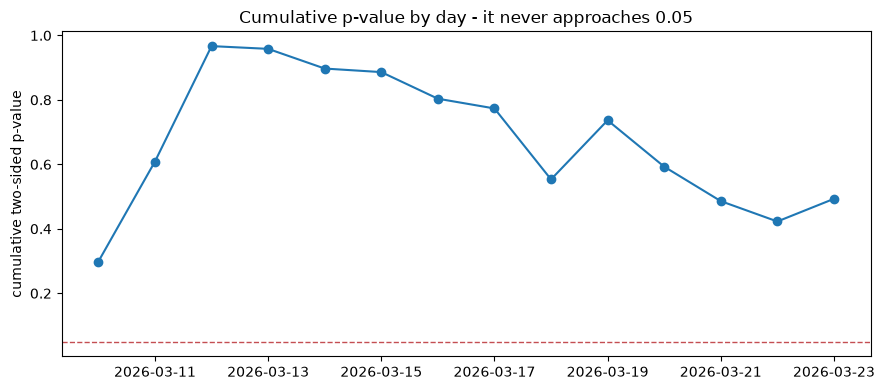

In [32]:
plt.figure(figsize=(9, 4))
plt.plot(daily.index, daily["p_value"], marker="o")
plt.axhline(0.05, color="#C44E52", linestyle="--", linewidth=1)
plt.ylabel("cumulative two-sided p-value")
plt.title("Cumulative p-value by day - it never approaches 0.05")
plt.tight_layout()
plt.show()

Two lessons: (1) the cumulative p-value never approaches 0.05 on any of the 14 days - its low
point is day 1 (p = 0.298 at n = 20 vs 9, where a 35% vs 56% start is meaningless), and the last
three readouts sit between 0.42 and 0.49, so even a team peeking daily would not have false-alarmed
here; (2) the point estimate itself drifted - roughly 0 pp through the first week, widening to
+3-4 pp late in the run. With ~14 users per arm per day (205/14 and 195/14) that drift is well
inside noise, and it is one more reason the readout stays inconclusive rather than becoming a story
about "the variant warming up".

## 10. Secondary metric — the checkout funnel

In [33]:
funnel = df.groupby(["variant", "event_name"])["session_id"].nunique().unstack(fill_value=0)
funnel = funnel[["page_view", "checkout_start", "checkout_complete", "drop_off"]]
funnel

event_name,page_view,checkout_start,checkout_complete,drop_off
variant,,,,
Control_A,205,205,96,109
Variant_B,195,195,98,97


In [34]:
funnel_pct = funnel.copy()
funnel_pct[["checkout_complete", "drop_off"]] = (
    funnel[["checkout_complete", "drop_off"]].div(funnel["page_view"], axis=0) * 100).round(2)
funnel_pct

event_name,page_view,checkout_start,checkout_complete,drop_off
variant,,,,
Control_A,205,205,46.8300,53.1700
Variant_B,195,195,50.2600,49.7400


The funnel skeleton is degenerate in an informative way: **100% of sessions in both arms go
page_view → checkout_start** — there is no measured drop between viewing and starting checkout in
either variant, so the entire experiment plays out at the single step-1 branch:
complete vs drop_off. Whatever Variant_B changed, it did not change *starting* behaviour.

## 11. Guardrail — session duration

In [35]:
dur = users.groupby("variant")["session_duration_sec"].agg(["count", "mean", "median", "std"])
dur.round(1)

,count,mean,median,std
variant,,,,
Control_A,205,40.0000,39.0000,9.6000
Variant_B,195,40.5000,40.0000,10.3000


In [36]:
t_stat, p_welch = stats.ttest_ind(B["session_duration_sec"], A["session_duration_sec"],
                                  equal_var=False)
print("mean duration A: %.1fs | B: %.1fs | difference %+.1fs"
      % (A["session_duration_sec"].mean(), B["session_duration_sec"].mean(),
         B["session_duration_sec"].mean() - A["session_duration_sec"].mean()))
print("Welch t = %.3f, p = %.3f" % (t_stat, p_welch))

mean duration A: 40.0s | B: 40.5s | difference +0.5s
Welch t = 0.507, p = 0.612


In [37]:
dur_by_outcome = users.groupby(["variant", "converted"])["session_duration_sec"].mean().unstack()
dur_by_outcome.round(1)

converted,0,1
variant,,
Control_A,36.6000,43.8000
Variant_B,35.5000,45.4000


**Guardrail neutral:** mean session duration 40.0s (A) vs 40.5s (B), Welch p = 0.612.
Converted sessions take longer than dropped ones in both arms (~44–45s vs ~36s) simply because
completion is the last step of the funnel — a mechanical artefact, not engagement evidence.

## 12. Heterogeneity I — device (where the average misleads)

In [38]:
def subgroup_table(frame, col):
    rows = []
    for name, g in frame.groupby(col):
        a = g[g["variant"] == "Control_A"]
        b = g[g["variant"] == "Variant_B"]
        pa, pb = a["converted"].mean(), b["converted"].mean()
        se = np.sqrt(pa * (1 - pa) / len(a) + pb * (1 - pb) / len(b))
        d = (pb - pa) * 100
        rows.append({col: name, "n_A": len(a), "rate_A_pct": round(pa * 100, 2),
                     "n_B": len(b), "rate_B_pct": round(pb * 100, 2),
                     "diff_pp": round(d, 2),
                     "ci_low": round(d - 1.96 * se * 100, 2),
                     "ci_high": round(d + 1.96 * se * 100, 2),
                     "p_value": round(2 * stats.norm.sf(abs((pb - pa) / se)), 4)})
    return pd.DataFrame(rows)

device_table = subgroup_table(users, "device_type")
device_table

,device_type,n_A,rate_A_pct,n_B,rate_B_pct,diff_pp,ci_low,ci_high,p_value
0,Desktop,98,51.0200,91,65.9300,14.9100,1.0300,28.8000,0.0353
1,Mobile,82,37.8000,81,27.1600,-10.6400,-24.9300,3.6400,0.1441
2,Tablet,25,60.0000,23,69.5700,9.5700,-17.3100,36.4400,0.4855


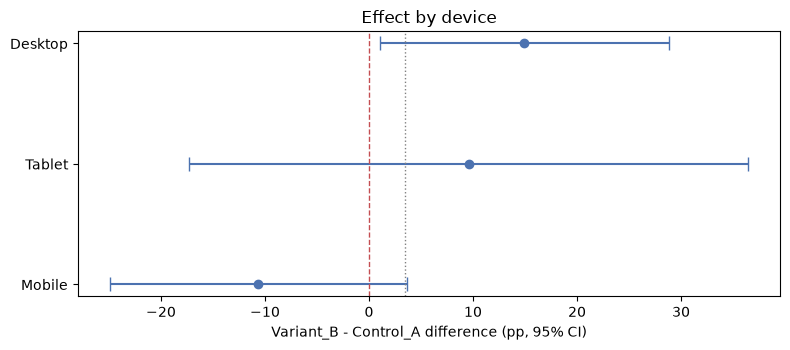

In [39]:
device_table_sorted = device_table.sort_values("diff_pp")
plt.figure(figsize=(8, 3.6))
plt.errorbar(device_table_sorted["diff_pp"], device_table_sorted["device_type"],
             xerr=[device_table_sorted["diff_pp"] - device_table_sorted["ci_low"],
                   device_table_sorted["ci_high"] - device_table_sorted["diff_pp"]],
             fmt="o", color="#4C72B0", capsize=5)
plt.axvline(0, color="#C44E52", linestyle="--", linewidth=1)
plt.axvline(diff_pp, color="grey", linestyle=":", linewidth=1)
plt.xlabel("Variant_B - Control_A difference (pp, 95% CI)")
plt.title("Effect by device")
plt.tight_layout()
plt.show()

The headline +3.43 pp is an average of **opposite signs**:

| Device | Control_A | Variant_B | Difference | p |
|---|---|---|---|---|
| Desktop | 51.02% (98) | 65.93% (91) | **+14.91 pp** | 0.035 |
| Tablet | 60.00% (25) | 69.57% (23) | +9.57 pp | 0.485 |
| Mobile | 37.80% (82) | 27.16% (81) | **−10.64 pp** | 0.144 |

Discipline check before believing any of them: three device tests means a Bonferroni threshold of
0.05 / 3 = **0.0167** — Desktop's 0.035 does **not** survive it, and Mobile's interval (−24.9 to
+3.6 pp) is wide. So no device claim is proven on its own. The formal test of "does the effect
differ by device at all" is the interaction — next cell.

In [40]:
interaction = None
try:
    import statsmodels.formula.api as smf
    m = users.assign(variant_bin=(users["variant"] == "Variant_B").astype(int))
    fit = smf.logit("converted ~ variant_bin * device_type", data=m).fit(disp=0)
    interaction = pd.DataFrame({"coef": fit.params, "p_value": fit.pvalues}).round(3)
except Exception as e:
    print("statsmodels not available (%s) - rely on the per-device table above." % e)
interaction

,coef,p_value
Intercept,0.0410,0.8400
device_type[T.Mobile],-0.5390,0.0770
device_type[T.Tablet],0.3650,0.4230
variant_bin,0.6200,0.0390
variant_bin:device_type[T.Mobile],-1.1080,0.0140
variant_bin:device_type[T.Tablet],-0.1980,0.7700


**The variant × Mobile interaction is significant (coef −1.108, p = 0.014):** Variant_B's
effect on Mobile is genuinely different from its effect on Desktop — this is not three noisy
subgroups, it is evidence the treatment behaves differently on mobile. Combined with Mobile's
negative point estimate, that is a *do-not-ship-to-mobile* signal, and a strong hypothesis for
what to debug (the variant's mobile experience) before any re-run. The Desktop gain stays
hypothesis-generating only: it does not survive multiple-comparison correction on its own.

## 13. Heterogeneity II — segment

In [41]:
segment_table = subgroup_table(users, "user_segment")
segment_table

,user_segment,n_A,rate_A_pct,n_B,rate_B_pct,diff_pp,ci_low,ci_high,p_value
0,Enterprise,29,51.7200,40,55.0000,3.2800,-20.5700,27.1200,0.7877
1,Free,114,44.7400,105,49.5200,4.7900,-8.4300,18.0100,0.4779
2,Premium,62,48.3900,50,48.0000,-0.3900,-19.0000,18.2300,0.9675


Segments are flat: Enterprise +3.28 pp (p = 0.788), Free +4.79 pp (p = 0.478), Premium
−0.39 pp (p = 0.967), and the variant × segment interaction terms are all non-significant
(p = 0.81 and 0.91 — `verify_analysis.py` fits that model, since the cell above fits only the
device interaction). Unlike device, there is no segment story here — the heterogeneity in this
experiment lives on the device axis only.

## 14. Bayesian cross-check

In [42]:
rng = np.random.default_rng(42)
post_a = rng.beta(1 + A["converted"].sum(), 1 + len(A) - A["converted"].sum(), 400_000)
post_b = rng.beta(1 + B["converted"].sum(), 1 + len(B) - B["converted"].sum(), 400_000)
p_b_better = (post_b > post_a).mean()
loss_ship_b = np.maximum(post_a - post_b, 0).mean() * 100
loss_ship_a = np.maximum(post_b - post_a, 0).mean() * 100
print("P(Variant_B rate > Control_A rate) = %.1f%%" % (p_b_better * 100))
print("expected loss if we ship B and B is actually worse: %.2f pp" % loss_ship_b)
print("expected loss if we keep A and B is actually better: %.2f pp" % loss_ship_a)

P(Variant_B rate > Control_A rate) = 75.3%
expected loss if we ship B and B is actually worse: 0.73 pp
expected loss if we keep A and B is actually better: 4.12 pp


The Bayesian read is softer but consistent: a ~75% posterior probability that B is better,
with a small expected loss (0.73 pp) if B is shipped and turns out worse — because the posterior
is centred near zero either way. Crucially, this posterior is **pooled across devices**: it averages
away the mobile interaction, which is precisely the part of the data a ship decision must not
average away. Bayesian and frequentist views reconcile to the same action once the device split
is respected.

## 15. Decision

### Verdict: **Do not ship — the result is inconclusive, and Mobile is a live concern.**

1. **Primary metric not significant.** +3.43 pp, p = 0.493, 95% CI −6.37 to +13.22 pp. The
   interval includes meaningful harm; a ship call on this is a coin flip dressed as a result.
2. **The run was severely underpowered.** ~10% power for the observed effect; minimum detectable
   effect ≈ 14 pp. Four hundred users cannot adjudicate a 3–5 pp checkout question at a ~47%
   baseline — that needs ≈ 1,566 users per arm for +5 pp (≈ 3,335 per arm for +3.43 pp).
3. **Assignment was valid** (SRM p = 0.617, balance p ≥ 0.20, zero contamination), so the
   inconclusiveness is a sample-size problem, not a data problem.
4. **Device interaction is the one real signal** (variant × Mobile p = 0.014). Desktop's
   +14.91 pp is promising but unproven after Bonferroni; Mobile's −10.64 pp point estimate
   says the variant may actively hurt the highest-drop-off cohort.

### Recommended next steps
- **Debug Variant_B on Mobile first** — session replay / device QA on the step-1 experience —
  before spending any more traffic.
- **Re-run pre-registered:** primary metric fixed as user-level checkout completion, target
  effect +5 pp, ≈ 1,566 users per arm, whole-week runtime, device declared a pre-specified
  subgroup, single end-of-run readout.
- **Do not** simply extend this run and re-read it — that converts a clean inconclusive result
  into a peeked one.

## 16. Limitations
- 400 users / 14 days: wide intervals everywhere; every subgroup cell is small (Tablet n = 48).
- One session per user in these logs — no repeat-visit or long-term retention readout is possible.
- The logs do not record what Variant_B changed; effect *mechanisms* (why Mobile differs) cannot
  be established from telemetry alone.
- Duration is elapsed time at the last event, not active engagement time.
- The logs are synthetic and anonymized (see the README's Data provenance section), so this is a
  worked method, not evidence about a real checkout.